# Phase 3 — Association Rules with DIC (Dynamic Itemset Counting)
**Student:** Jeswin Tobias J &nbsp;|&nbsp; **Roll No:** CS23I1013
**Input:** `outputs/transactions.txt` — 52,416 transactions (one per 10-min reading), 35 items, ~11 items each (Phase 1)

### DIC in brief
- Apriori scans the data once per itemset size. DIC places **stations every M transactions** and can **start counting a k-itemset at any station**, as soon as all its (k−1)-subsets look frequent. The train analogy: itemsets get on at a station and get off at the same station one full lap later.
- Four states: **DC** dashed circle (counting, below minsup) → **DS** dashed square (counting, already ≥ minsup) → **SS** solid square (finished, frequent) or **SC** solid circle (finished, infrequent).
- Result = same frequent itemsets as Apriori, in **fewer passes** over the data.

### Parameters (assumed & stated)
| Parameter | Value | Reason |
|---|---|---|
| min support | **10 %** (5,242 transactions) | from the Phase 1 item-support plot: keeps patterns up to 6 items (768 itemsets); 5 % → 3,742 (unreadable), 20 % → 106 (mostly obvious) |
| min confidence | **70 %** | rule must hold in at least 7 of 10 matching readings |
| M (station interval) | **5,000** (≈ 10 % of data) | main run; a sensitivity study tests M = 500 … 52,416 |
| Order | chronological | the natural order of the readings; shuffled order is tested too |

In [1]:
import sys; sys.path.append('..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from mlxtend.frequent_patterns import apriori as mlx_apriori
from src.common import *
from src.arm import encode, dic, apriori_counts, generate_rules, drop_redundant

set_style(); header()
pd.set_option('display.width', 180, 'display.max_colwidth', 80)
MIN_SUP, MIN_CONF, M = 0.10, 0.70, 5000

Jeswin Tobias J | CS23I1013 | ASBD Hackathon — Tetouan Power Consumption


## 1. Load transactions

In [2]:
T = [line.split(',') for line in (OUTPUTS / 'transactions.txt').read_text().splitlines()]
X, items = encode(T)
N = len(X)
print(f'{N} transactions x {len(items)} items | min support count = {int(np.ceil(MIN_SUP*N))}')
print('Items:', items)

52416 transactions x 35 items | min support count = 5242
Items: ['Afternoon', 'Autumn', 'Evening', 'Holiday', 'Hum=High', 'Hum=Low', 'Hum=Med', 'Morning', 'Night', 'Ramadan', 'Solar=Dark', 'Solar=High', 'Solar=Low', 'Spring', 'Summer', 'Temp=High', 'Temp=Low', 'Temp=Med', 'Total=High', 'Total=Low', 'Total=Med', 'Weekend', 'Wind=Calm', 'Wind=Windy', 'Winter', 'Workday', 'Z1=High', 'Z1=Low', 'Z1=Med', 'Z2=High', 'Z2=Low', 'Z2=Med', 'Z3=High', 'Z3=Low', 'Z3=Med']


## 2. Run DIC (M = 5,000, chronological order)

In [3]:
freq, log, stats = dic(X, MIN_SUP, M)
print({k: round(v, 3) if isinstance(v, float) else v for k, v in stats.items()})
log[['station', 'read', 'passes', 'new_DC', 'DC', 'DS', 'SS', 'SC']].head(12)

{'time_s': 0.683, 'passes': 5.572, 'stations': 61, 'itemsets_counted': 1575, 'frequent': 768, 'max_active_counters': 831}


,station,read,passes,new_DC,DC,DS,SS,SC
0,1,5000,0.095391,0,35,0,0,0
1,2,10000,0.190781,10,40,5,0,0
2,3,15000,0.286172,95,125,15,0,0
3,4,20000,0.381563,85,204,21,0,0
4,5,25000,0.476954,188,383,30,0,0
5,6,30000,0.572344,119,497,35,0,0
6,7,35000,0.667735,1,494,39,0,0
7,8,40000,0.763126,5,486,52,0,0
8,9,45000,0.858516,42,513,67,0,0
9,10,50000,0.953907,44,533,91,0,0


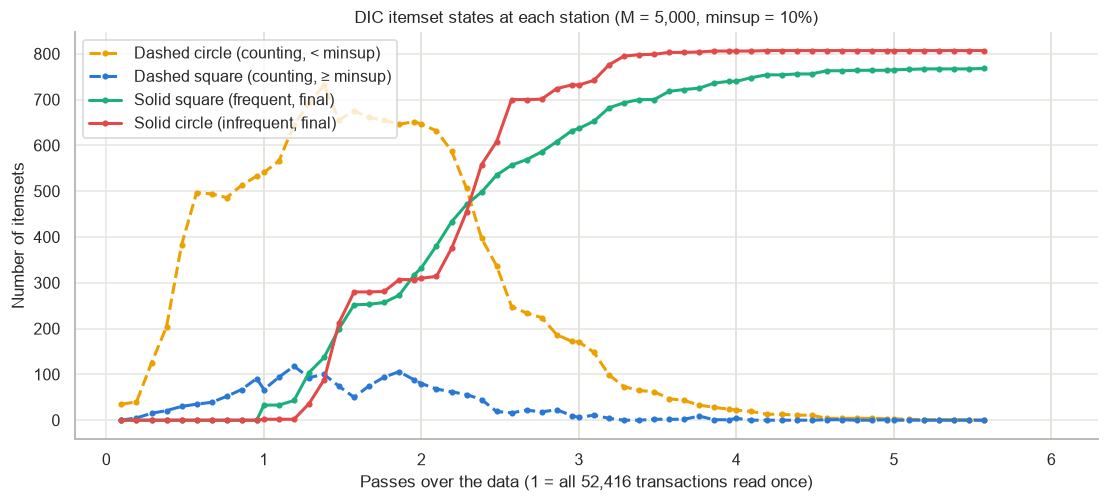

In [4]:
# How itemset states evolve as the "train" moves through the data
fig, ax = plt.subplots(figsize=(12, 4.8))
for st, lab, c, ls in [('DC', 'Dashed circle (counting, < minsup)', CAT[3], '--'), ('DS', 'Dashed square (counting, ≥ minsup)', CAT[0], '--'),
                       ('SS', 'Solid square (frequent, final)', CAT[2], '-'), ('SC', 'Solid circle (infrequent, final)', CAT[7], '-')]:
    ax.plot(log.passes, log[st], color=c, ls=ls, lw=2, marker='o', ms=3, label=lab)
for p in range(1, int(np.ceil(log.passes.max())) + 1):
    ax.axvline(p, color='#d4d3cd', lw=1, zorder=0)
ax.set(title=f'DIC itemset states at each station (M = {M:,}, minsup = {MIN_SUP:.0%})',
       xlabel='Passes over the data (1 = all 52,416 transactions read once)', ylabel='Number of itemsets')
ax.legend(loc='upper left')
save_fig('21_dic_itemset_states'); plt.show()

**Inferences:**
- 2-itemsets start counting at the **2nd station (10,000 transactions)**, long before the first pass ends. Apriori would wait for the full pass.
- At the end of pass 1, all 1-itemsets are solid: 33 frequent and 2 infrequent (**Holiday** 4.1 %, **Ramadan** 8.2 % — below 10 %).
- Dashed circles peak at ≈ 720 itemsets around pass 1.4 (largest working set); everything is settled after **5.57 passes**.

## 3. Correctness and comparison with Apriori
Two checks: DIC must give exactly the same itemsets and counts as (a) a reference library (mlxtend Apriori) and (b) a level-wise Apriori written on the same counting engine, which gives a fair pass and time comparison.

In [5]:
ref = mlx_apriori(pd.DataFrame(X, columns=items), min_support=MIN_SUP, use_colnames=True)
ref_set = {frozenset(s): round(sup * N) for s, sup in zip(ref.itemsets, ref.support)}
dic_set = {frozenset(items[i] for i in s): c for s, c in freq.items()}
print('Same itemsets as mlxtend:', set(ref_set) == set(dic_set), '| same counts:', all(ref_set[k] == dic_set[k] for k in dic_set))

freq_ap, stats_ap = apriori_counts(X, MIN_SUP)
print('Same itemsets as own Apriori:', set(freq_ap) == set(freq))
cmp = pd.DataFrame({'DIC (M=5,000)': stats, 'Apriori': stats_ap}).loc[['passes', 'itemsets_counted', 'frequent', 'max_active_counters', 'time_s']]
cmp.round(3)   # max_active_counters: itemsets held in memory at once (Apriori = largest level)

Same itemsets as mlxtend: True | same counts: True
Same itemsets as own Apriori: True


,"DIC (M=5,000)",Apriori
passes,5.572,6.000
itemsets_counted,1575.000,1575.000
frequent,768.000,768.000
max_active_counters,831.000,686.000
time_s,0.683,0.178


In [6]:
sizes = pd.Series([len(s) for s in freq]).value_counts().sort_index()
print('Frequent itemsets by size:', sizes.to_dict())

Frequent itemsets by size: {1: 33, 2: 224, 3: 281, 4: 172, 5: 52, 6: 6}


## 4. Sensitivity — station interval M and data order
Smaller M = more stations = itemsets board earlier (fewer passes) but more checkpoint overhead. M = N is a single station per pass, so DIC behaves like Apriori.
DIC works best on **homogeneous** data; our readings are in time order (seasons), so a shuffled copy is tested too.

In [7]:
rng = np.random.default_rng(SEED)
X_shuf = X[rng.permutation(N)]
rows = []
for m in [500, 1000, 2000, 5000, 10000, 13104, 26208, N]:
    for order, XX in [('Chronological', X), ('Shuffled', X_shuf)]:
        _, _, s = dic(XX, MIN_SUP, m)
        rows.append({'M': m, 'order': order, **s})
sens = pd.DataFrame(rows)
sens.to_csv(OUTPUTS / 'dic_sensitivity.csv', index=False)
sens.pivot(index='M', columns='order', values=['passes', 'time_s', 'max_active_counters']).round(2)

passes                 time_s          max_active_counters         
order Chronological Shuffled Chronological Shuffled       Chronological Shuffled
M                                                                               
500            4.92     5.01          4.44     4.49               980.0   1109.0
1000           4.95     5.02          2.33     2.43               967.0   1105.0
2000           4.95     5.08          1.27     1.34               940.0   1071.0
5000           5.57     5.19          0.68     0.65               831.0   1017.0
10000          5.57     5.38          0.44     0.44               798.0    833.0
13104          5.75     5.50          0.35     0.32               756.0    831.0
26208          6.00     5.50          0.25     0.26               667.0    688.0
52416          6.00     6.00          0.22     0.22               686.0    686.0

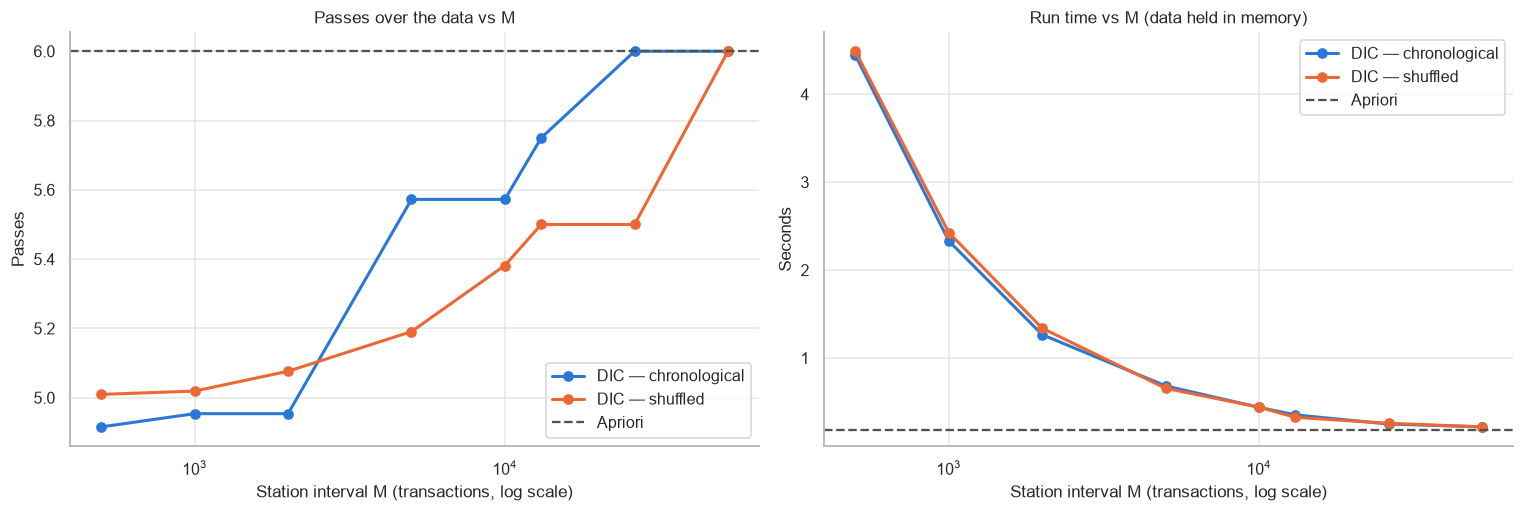

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for order, c in [('Chronological', CAT[0]), ('Shuffled', CAT[1])]:
    d = sens[sens.order == order]
    axes[0].plot(d.M, d.passes, marker='o', color=c, lw=2, label=f'DIC — {order.lower()}')
    axes[1].plot(d.M, d.time_s, marker='o', color=c, lw=2, label=f'DIC — {order.lower()}')
axes[0].axhline(stats_ap['passes'], color='#52514e', ls='--', lw=1.5, label='Apriori')
axes[1].axhline(stats_ap['time_s'], color='#52514e', ls='--', lw=1.5, label='Apriori')
for ax in axes:
    ax.set_xscale('log'); ax.set_xlabel('Station interval M (transactions, log scale)'); ax.legend()
axes[0].set(title='Passes over the data vs M', ylabel='Passes')
axes[1].set(title='Run time vs M (data held in memory)', ylabel='Seconds')
fig.tight_layout(); save_fig('22_dic_passes_time_vs_M'); plt.show()

**Inferences:**
- **Correctness:** DIC gives exactly the same 768 itemsets and counts as mlxtend and as our Apriori.
- **Passes:** DIC needs fewer passes as M shrinks: **4.92 at M = 500 vs 6.0 for Apriori (−18 %)**. With M = N (one station per pass) DIC degenerates to Apriori, as theory predicts.
- **Time:** in memory, DIC is *slower* (0.63 s at M = 5,000, 4.2 s at M = 500, vs 0.18 s for Apriori), because every station adds bookkeeping. DIC pays off when a **pass is expensive** (disk / distributed data); with RAM-resident data a scan is cheap. This trade-off motivates the PySpark phase.
- **Memory:** DIC holds up to 831 counters at once vs 686 for Apriori's largest level (+21 %; 980–1,109 at M = 500).
- **Order:** shuffled data needs fewer passes at medium M (5.19 vs 5.57 at M = 5,000). Chronological blocks are seasonal, so early stations under-represent summer patterns — DIC's known weakness on non-homogeneous data.

## 5. Association rules
For every frequent itemset S and non-empty subset A: rule A → S−A with
**support** = P(S), **confidence** = P(S)/P(A), **lift** = confidence / P(S−A) (lift > 1 = positive association).
Redundant rules are removed: A → C is dropped if a smaller antecedent A′ ⊂ A already gives A′ → C with equal or higher confidence.

In [9]:
rules_all = generate_rules(freq, N, items, MIN_CONF)
rules = drop_redundant(rules_all).sort_values('lift', ascending=False).reset_index(drop=True)
rules['rule'] = rules.A + '  →  ' + rules.C
print(f'Rules with confidence >= {MIN_CONF:.0%}: {len(rules_all)} | non-redundant: {len(rules)} | lift > 1: {(rules.lift > 1).sum()}')
rules[['rule', 'support', 'confidence', 'lift', 'leverage']].to_csv(OUTPUTS / 'dic_rules.csv', index=False)
# Same itemset appears in many A/C splits -> show the best rule per distinct itemset
rules['itemset'] = [tuple(sorted(a | c)) for a, c in zip(rules.antecedent, rules.consequent)]
print('Distinct itemsets behind the rules:', rules.itemset.nunique())
rules.drop_duplicates('itemset')[['rule', 'support', 'confidence', 'lift']].head(15).round(3)

Rules with confidence >= 70%: 1800 | non-redundant: 1098 | lift > 1: 1098
Distinct itemsets behind the rules: 457


,rule,support,confidence,lift
0,"Temp=High, Z1=High, Z3=High → Summer, Total=High, Z2=High",0.103,0.757,5.960
4,"Temp=High, Z1=High, Z3=High → Summer, Z2=High",0.103,0.757,5.931
15,"Summer, Z2=High → Temp=High, Total=High, Z1=High",0.104,0.817,5.507
17,"Summer, Z2=High → Temp=High, Total=High, Z3=High",0.112,0.880,5.481
21,"Summer, Total=High → Temp=High, Z1=High, Z3=High",0.115,0.715,5.242
25,"Summer, Z2=High → Total=High, Wind=Windy, Z3=High",0.100,0.784,5.186
27,"Summer, Z2=High → Temp=High, Total=High",0.113,0.888,5.120
32,"Summer, Total=High, Wind=Windy → Temp=High, Z3=High",0.118,0.963,4.993
33,"Wind=Windy, Z2=High, Z3=High → Temp=High, Total=High",0.107,0.864,4.980
35,"Summer, Z1=High → Temp=High, Total=High",0.118,0.857,4.939


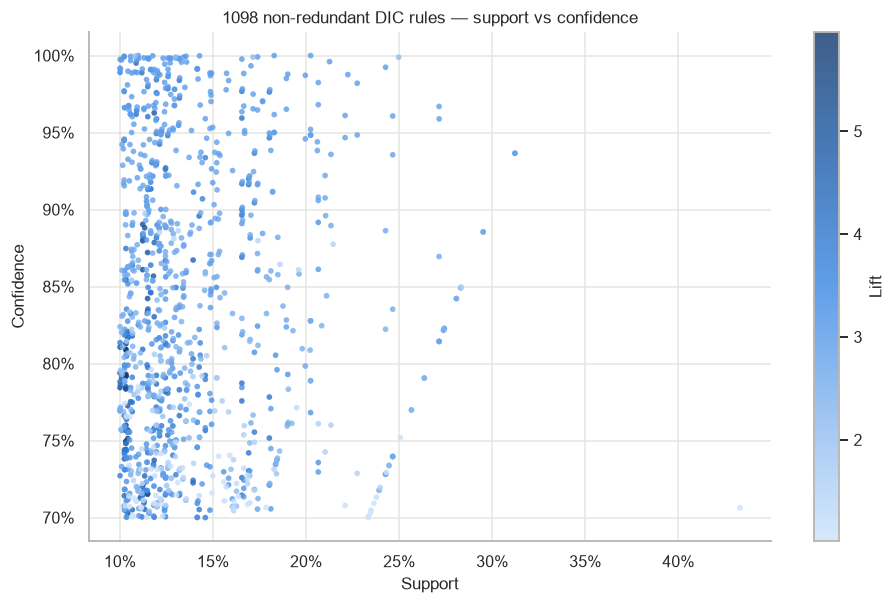

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(rules.support, rules.confidence, c=rules.lift, cmap='seq_blue', s=14, alpha=0.8, linewidths=0)
fig.colorbar(sc, ax=ax, label='Lift')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set(title=f'{len(rules)} non-redundant DIC rules — support vs confidence', xlabel='Support', ylabel='Confidence')
save_fig('23_dic_rules_support_confidence'); plt.show()

**Inferences:**
- 1,800 rules pass 70 % confidence; removing redundant ones leaves **1,098** (39 % redundant), built from 457 distinct itemsets. All have lift > 1.
- The highest-lift rules (≈ 5–6) all describe one pattern: **{Summer, Temp=High, Z1/Z2/Z3/Total=High}**. In hot summer periods all three zones are high **at the same time**.
- Most rules sit at 10–15 % support; the strongest lifts are at low support. Broad (high-support) rules are closer to independence.

### 6.1 Rules that explain demand: context → load
Most useful rules have **only context items** (weather, time, day) on the left and **only load items** (Z1/Z2/Z3/Total) on the right — they answer "under which conditions is demand high/low?".

In [11]:
is_load = lambda i: i.startswith(('Z1', 'Z2', 'Z3', 'Total'))
ctx_load = rules[rules.antecedent.map(lambda s: all(not is_load(items[i]) for i in s)) &
                 rules.consequent.map(lambda s: all(is_load(items[i]) for i in s))]
print('Context -> load rules:', len(ctx_load))
for lvl in ['High', 'Low']:
    sub = ctx_load[ctx_load.C.str.contains(f'Total={lvl}')]
    print(f'\nTop rules predicting Total={lvl} ({len(sub)} rules):')
    display(sub[['rule', 'support', 'confidence', 'lift']].head(8).round(3))

Context -> load rules: 43

Top rules predicting Total=High (8 rules):


,rule,support,confidence,lift
502,"Evening, Workday → Total=High, Z1=High, Z2=High",0.125,0.726,2.944
614,"Evening, Workday → Total=High, Z2=High",0.129,0.749,2.844
692,"Evening → Total=High, Z2=High",0.180,0.721,2.737
695,"Evening, Workday → Total=High, Z1=High",0.138,0.806,2.732
704,"Evening → Total=High, Z1=High",0.200,0.798,2.705
814,"Evening, Workday → Total=High",0.146,0.848,2.543
819,Evening → Total=High,0.211,0.844,2.532
950,"Summer, Temp=High, Wind=Windy → Total=High",0.120,0.707,2.121



Top rules predicting Total=Low (11 rules):


,rule,support,confidence,lift
400,"Night, Temp=Low → Total=Low, Z1=Low",0.102,0.945,3.028
618,"Night, Temp=Low → Total=Low",0.102,0.946,2.837
653,"Night, Wind=Calm → Total=Low, Z1=Low, Z2=Low",0.120,0.760,2.799
698,"Night, Wind=Calm → Total=Low, Z2=Low",0.122,0.771,2.722
717,"Night, Wind=Calm → Total=Low, Z1=Low",0.132,0.838,2.684
809,"Night, Wind=Calm → Total=Low",0.134,0.850,2.551
899,"Night, Workday → Total=Low, Z1=Low",0.126,0.733,2.349
907,"Night → Total=Low, Z1=Low",0.181,0.722,2.313


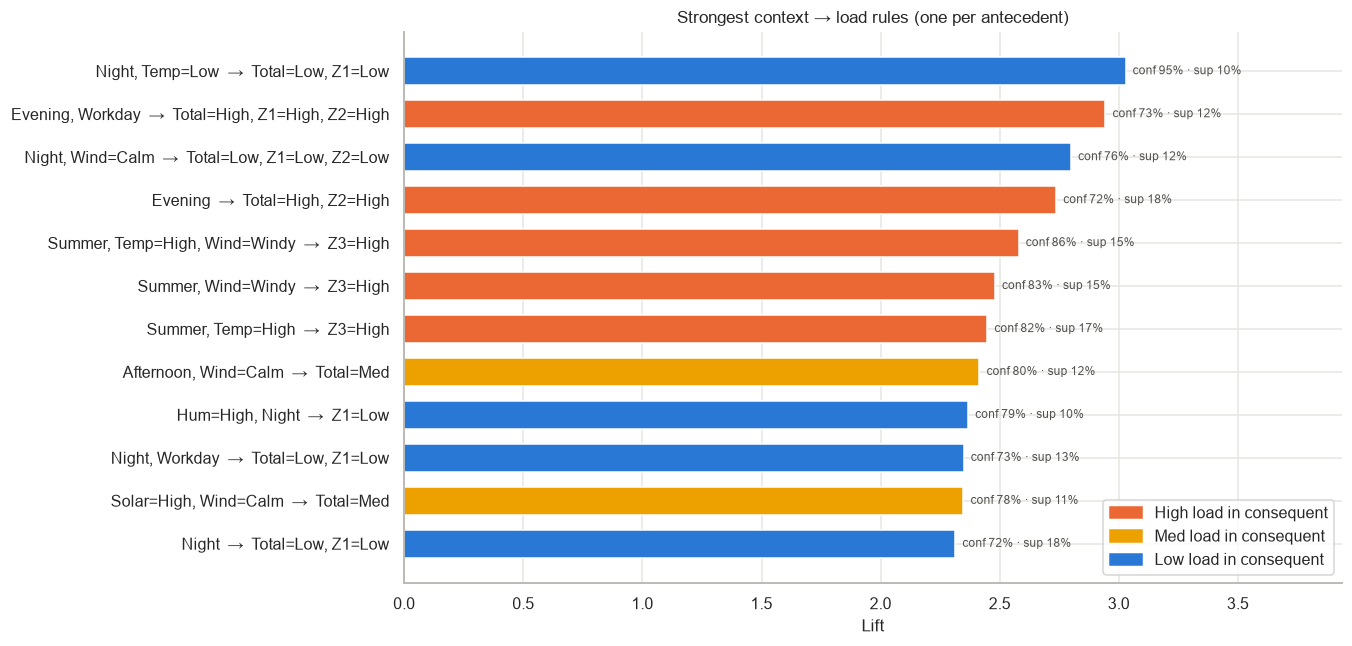

In [12]:
top = ctx_load.drop_duplicates('A').head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 6.5))
LVL_COL = {'High': CAT[1], 'Med': CAT[3], 'Low': CAT[0]}
level_of = lambda c: 'High' if 'High' in c else ('Med' if 'Med' in c else 'Low')
bars = ax.barh(top.rule, top.lift, color=[LVL_COL[level_of(c)] for c in top.C], height=0.65)
for b, (cf, sp) in zip(bars, zip(top.confidence, top.support)):
    ax.text(b.get_width() + 0.03, b.get_y() + b.get_height()/2, f'conf {cf:.0%} · sup {sp:.0%}', va='center', fontsize=8, color='#52514e')
ax.set(title='Strongest context → load rules (one per antecedent)', xlabel='Lift', xlim=(0, top.lift.max() * 1.3))
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=LVL_COL[k]) for k in LVL_COL],
          labels=[f'{k} load in consequent' for k in LVL_COL], loc='lower right')
save_fig('24_dic_top_context_load_rules'); plt.show()

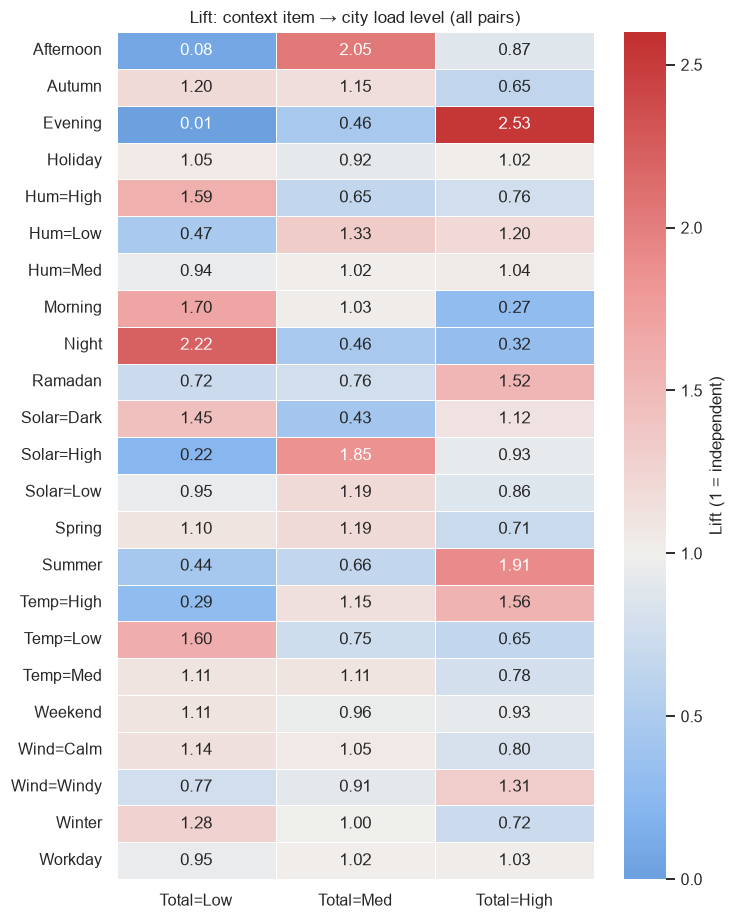

In [13]:
# Lift of every context item -> city load level, computed for ALL pairs straight from the transactions
col = {it: k for k, it in enumerate(items)}
ctx_items = sorted(i for i in items if not is_load(i))
levels = ['Total=Low', 'Total=Med', 'Total=High']
L = pd.DataFrame([[(X[:, col[a]] & X[:, col[b]]).mean() / (X[:, col[a]].mean() * X[:, col[b]].mean()) for b in levels]
                  for a in ctx_items], index=ctx_items, columns=levels)
fig, ax = plt.subplots(figsize=(7, 10))
sns.heatmap(L, cmap='div_br', center=1, vmin=0, vmax=2.6, annot=True, fmt='.2f', linewidths=0.5, linecolor='white',
            cbar_kws={'label': 'Lift (1 = independent)'}, ax=ax)
ax.set(title='Lift: context item → city load level (all pairs)', xlabel='', ylabel='')
save_fig('25_dic_lift_matrix_context_load'); plt.show()

**Inferences (context → load, 43 rules):**
- **Evening → Total=High**: confidence 84 %, lift 2.53, support 21 %. Evening almost never has low load (lift 0.01). The evening peak is the most reliable pattern in the data.
- **Night ∧ Temp=Low → Total=Low**: confidence **95 %**, lift 2.84 — cold nights are the city's minimum-demand state.
- **Summer ∧ Temp=High ∧ Wind=Windy → Z3=High**: confidence 86 % — Zone 3's summer surge, confirmed as a rule.
- **Afternoon ∧ Wind=Calm → Total=Med** (80 %): daytime is a stable middle level.
- Lift matrix: **Ramadan → Total=High lift 1.52**, but Ramadan is below 10 % support, so DIC cannot turn it into a rule (stated limitation). Holiday ≈ 1.0 and Weekend 1.11 (low) have little effect at city level.

## 6. Summary

| Aspect | Result |
|---|---|
| Parameters | minsup 10 %, minconf 70 %, M = 5,000 (assumed) |
| Frequent itemsets | 768 (sizes 1–6), identical to Apriori and mlxtend |
| Passes | DIC 5.57 (M = 5,000), 4.92 (M = 500) vs Apriori 6.0 → up to 18 % fewer scans |
| Cost | more stations → more bookkeeping and counters; slower in RAM, better when scans are expensive |
| Rules | 1,800 → 1,098 non-redundant; 43 context → load rules |
| Key rules | Evening → High (84 %); cold Night → Low (95 %); hot windy Summer → Zone 3 High (86 %) |
| Limitation | Ramadan / Holiday below 10 % support → no rules (Ramadan lift 1.52 seen in the pair matrix) |